In [2]:
import time
import tensorflow as tf
import numpy as np
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelBinarizer
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from tensorflow.keras.callbacks import EarlyStopping


In [3]:
# Load CIFAR-10 dataset
cifar10 = tf.keras.datasets.cifar10
(train_images, train_labels), (test_images, test_labels) = cifar10.load_data()
#print(train_images.shape, train_labels.shape, test_images.shape, test_labels.shape)

# Split training data into training and validation sets (before any processing)
train_images, val_images, train_labels, val_labels = train_test_split(
    train_images, train_labels, test_size=0.2, random_state=31)

# Normalize the data
train_images = train_images / 255.0
val_images = val_images / 255.0
test_images = test_images / 255.0

# Flatten the images
train_images_flat = train_images.reshape(train_images.shape[0], -1)
val_images_flat = val_images.reshape(val_images.shape[0], -1)
test_images_flat = test_images.reshape(test_images.shape[0], -1)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [4]:
# Apply PCA
pca = PCA(n_components=107)
train_images_pca = pca.fit_transform(train_images_flat)
val_images_pca = pca.transform(val_images_flat)
test_images_pca = pca.transform(test_images_flat)

# Onehot encoding the labels
lb = LabelBinarizer()
train_labels_onehot = lb.fit_transform(train_labels)
val_labels_onehot = lb.transform(val_labels)
test_labels_onehot = lb.transform(test_labels)

In [5]:
# Create MLP model with 6 hidden layers
model = tf.keras.Sequential([
    tf.keras.Input(shape=(107,)),
    tf.keras.layers.Dense(4096, activation='relu'),
    tf.keras.layers.Dense(2048, activation='relu'),
    tf.keras.layers.Dense(1024, activation='relu'),
    tf.keras.layers.Dense(512, activation='relu'),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

In [6]:
# Compile the model
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [7]:
# Stop the training if the accuracy doesn't improve
early_stopping = EarlyStopping(monitor='val_accuracy',
                               patience=2,
                               restore_best_weights=True)

In [8]:
# Train the model
start_time = time.time()

Super_Duper_Model = model.fit(train_images_pca,
                              train_labels_onehot,
                              epochs=40,
                              batch_size=64,
                              validation_data=(val_images_pca, val_labels_onehot),
                              callbacks=[early_stopping])

end_time = time.time()
training_time = end_time - start_time
print(f"Training time (PCA): {training_time:.2f} seconds")

Epoch 1/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 7ms/step - accuracy: 0.3498 - loss: 1.8190 - val_accuracy: 0.4781 - val_loss: 1.4957
Epoch 2/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - accuracy: 0.5066 - loss: 1.3997 - val_accuracy: 0.5099 - val_loss: 1.4007
Epoch 3/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.5771 - loss: 1.2034 - val_accuracy: 0.5339 - val_loss: 1.3486
Epoch 4/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.6342 - loss: 1.0409 - val_accuracy: 0.5536 - val_loss: 1.3425
Epoch 5/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.6871 - loss: 0.8806 - val_accuracy: 0.5558 - val_loss: 1.3619
Epoch 6/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7394 - loss: 0.7440 - val_accuracy: 0.5504 - val_loss: 1.5018
Epoch 7/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.7891 - loss: 0.6054 - val_accuracy: 0.5581 - val_loss: 1.4990
Epoch 8/30
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8342 - loss: 0.4772 - val_accuracy: 0.

In [9]:
# Testing/evaluating the model
test_loss, test_accuracy = model.evaluate(test_images_pca, test_labels_onehot)
print(f"Test accuracy: {test_accuracy*100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.5681 - loss: 1.6647
Test accuracy: 56.18%


In [10]:
class_names = [
    "airplane", "automobile", "bird", "cat",
    "deer", "dog", "frog", "horse", "ship", "truck"
]

# Get predictions and the true labels
predictions = model.predict(test_images_pca)
predicted_classes = np.argmax(predictions, axis=1)
true_classes = test_labels.flatten()

# Counters
correct = [0] * 10
total = [0] * 10

# Count correct predictions and total samples
for true, predicted in zip(true_classes, predicted_classes):
    total[true] += 1
    if true == predicted:
        correct[true] += 1

# Print results for each class
print("\nCorrectly classified samples per class:")
for i, class_name in enumerate(class_names):
    print(f"{class_name}: {correct[i]} out of {total[i]}")


313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

Correctly classified samples per class:
airplane: 661 out of 1000
automobile: 630 out of 1000
bird: 475 out of 1000
cat: 394 out of 1000
deer: 405 out of 1000
dog: 434 out of 1000
frog: 649 out of 1000
horse: 622 out of 1000
ship: 726 out of 1000
truck: 622 out of 1000


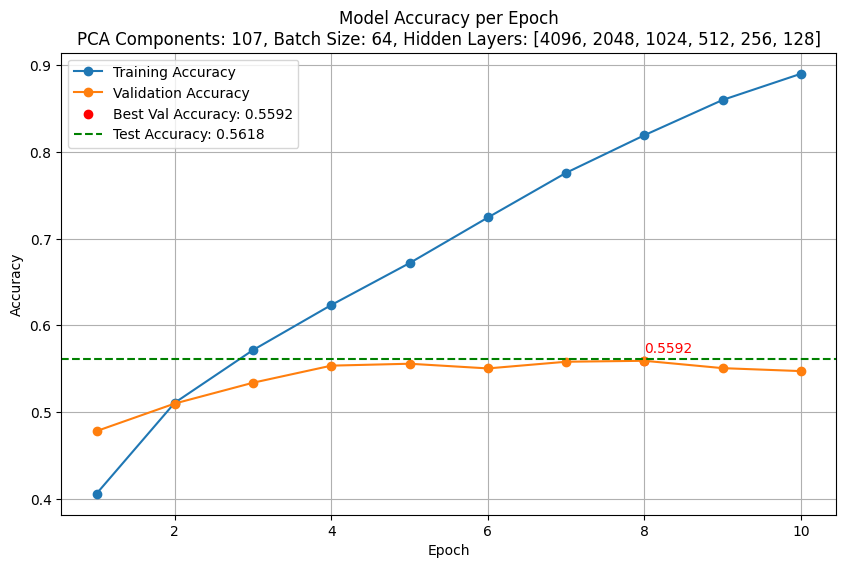

In [11]:
best_epoch = np.argmax(Super_Duper_Model.history['val_accuracy']) + 1
best_val_accuracy = Super_Duper_Model.history['val_accuracy'][best_epoch - 1]

pca_components = 107
batch_size = 64
hidden_layers = [4096, 2048, 1024, 512, 256, 128]

# Plot accuracies
plt.figure(figsize=(10, 6))
epochs = range(1, len(Super_Duper_Model.history['accuracy']) + 1)

# Plot training and validation accuracy
plt.plot(epochs, Super_Duper_Model.history['accuracy'], label='Training Accuracy', marker='o')
plt.plot(epochs, Super_Duper_Model.history['val_accuracy'], label='Validation Accuracy', marker='o')

# Highlight the best validation accuracy
plt.scatter(best_epoch, best_val_accuracy, color='red', label=f'Best Val Accuracy: {best_val_accuracy:.4f}')
plt.text(
    best_epoch,                    # The x-position is the best epoch
    best_val_accuracy + 0.01,      # The y-position is slightly above the accuracy line
    f'{best_val_accuracy:.4f}',
    color='red',
    fontsize=10
)

# Plot test accuracy
plt.axhline(y=test_accuracy, color='green', linestyle='--', label=f'Test Accuracy: {test_accuracy:.4f}')

# Title and labels
plt.title(f"Model Accuracy per Epoch\nPCA Components: {pca_components}, Batch Size: {batch_size}, Hidden Layers: {hidden_layers}")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.show()